# Monthly EM Update

This notebook is the single runbook for the market-data tables and charts used in the EM Updates slide workflow. PowerPoint assembly remains manual.

Run all cells from top to bottom. To prepare a different monthly update, change only `year` and `month` in the configuration cell. The notebook derives the reporting month, previous month, previous year, query windows, comparison labels, chart titles, and output filename from those values.

The main chart focus is NSW1 two-hour/four-hour battery assets and QLD1 two-hour battery assets. Price, generation, demand, and gas-weighted price outputs are produced for both target regions. Data is never automatically imputed; review the quality reports before using charts in slides.


## Configuration and API preflight

In [1]:
import calendar
import datetime as dt
import importlib
import os
import numpy as np

# API configuration. The endpoint is intentionally kept compatible with the original workflow.
os.environ['NEMPOINT_URL'] = 'https://www.neopoint.com.au/data/query'

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd

import helper_functions
importlib.reload(helper_functions)

from helper_functions import (
    aggregate_generation_to_half_hour,
    aggregate_to_half_hour,
    average_demand_by_half_hour,
    build_generation_profile,
    build_time_series_quality_report,
    calculate_gas_weighted_price,
    get_fueltype_generation,
    get_operational_demand,
    get_price_data,
    GetSpreads,
    half_hour_time_labels,
    pivot_format_data,
)

if not os.getenv('NEMPOINT_API_KEY'):
    raise RuntimeError('Set NEMPOINT_API_KEY before running this notebook.')

# Brand styling (Akaysha Energy Brand Guidelines, Nov 2024).
# Baikal is the brand typeface but isn't available outside licensed design tools;
# Inter is the brand's documented fallback for external software such as this notebook.
fm.fontManager.addfont('fonts/Inter.ttf')
plt.rcParams['font.family'] = 'Inter'

AKAYSHA_PINE = '#003723'
AKAYSHA_MOSS = '#00743C'
AKAYSHA_JADE = '#007864'   # 'Jade' in the brand spectrum
AKAYSHA_SPRING = '#46C86E'  # 'Spring' in the brand spectrum
AKAYSHA_LIME = '#C7F77A'
AKAYSHA_AMARANTH = '#E75751'
AKAYSHA_AMBER = '#F69B4E'
AKAYSHA_AQUA = '#99D9E7'
AKAYSHA_AZURE = '#509EE3'

# Monthly run configuration. Change year/month here only.
year = 2026
month = 8
target_regions = ['NSW1', 'QLD1']
target_durations = {'NSW1': [2, 4], 'QLD1': [2]}
regions = ['NSW1', 'QLD1', 'SA1', 'TAS1', 'VIC1']
durations = sorted({duration for values in target_durations.values() for duration in values})

if not 1 <= month <= 12:
    raise ValueError('month must be between 1 and 12')
if not set(target_regions).issubset(regions):
    raise ValueError(f'target_regions must be selected from {regions}')
if set(target_regions) != set(target_durations):
    raise ValueError('target_durations must define every target region')

month_name = calendar.month_name[month]
output_path = f'{month_name} {year} Spreads.csv'

month_start = dt.datetime(year, month, 1)
month_end = dt.datetime(year + (month == 12), (month % 12) + 1, 1)
previous_month_start = (month_start - dt.timedelta(days=1)).replace(day=1)
previous_month_end = month_start
previous_year_start = dt.datetime(year - 1, month, 1)
previous_year_end = dt.datetime(year - 1 + (month == 12), (month % 12) + 1, 1)

# All price charts need the reporting month and its previous month.
price_start = previous_month_start
price_end = month_end


## Price data and spreads

This section retrieves prices for the previous and reporting months, reports data quality, calculates daily spreads for all configured regions and durations, exports the daily spread table, and creates spread and price comparison charts.

In [2]:
# Retrieve the reporting month and previous month for price profiles and spreads.
price_data = get_price_data(price_start, price_end)
price_quality_report = build_time_series_quality_report(
    price_data,
    group_columns=['REGIONID'],
)
price_quality_report
price_data.to_csv('price_data.csv')

c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


In [3]:
price_table = pivot_format_data(price_data)
spreads, daily_spreads, spread_diagnostics = GetSpreads(
    price_table[regions],
    durations=durations,
    StartPeriods=[price_start.date()],
    EndPeriods=[price_end.date()],
    incomplete_day_policy='exclude',
    return_diagnostics=True,
)
spread_diagnostics


{'expected_intervals_per_day': 288,
 'available_day_count': 63,
 'valid_day_count': 62,
 'excluded_days': [{'date': '2026-06-30',
   'reason': 'expected 288 intervals, found 1'}]}

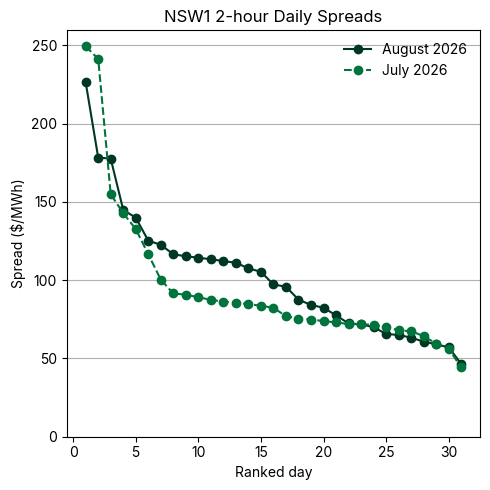

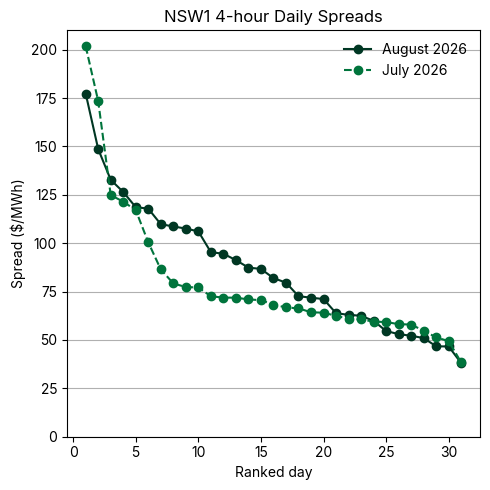

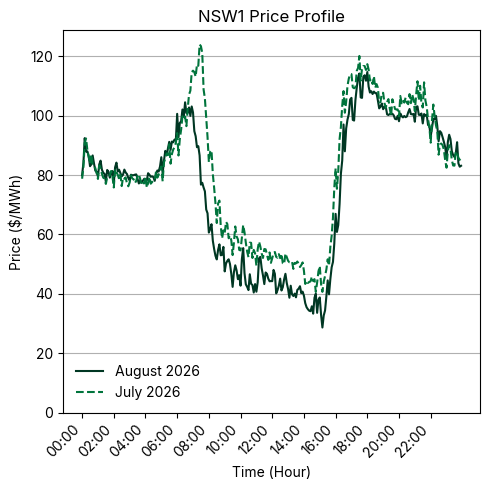

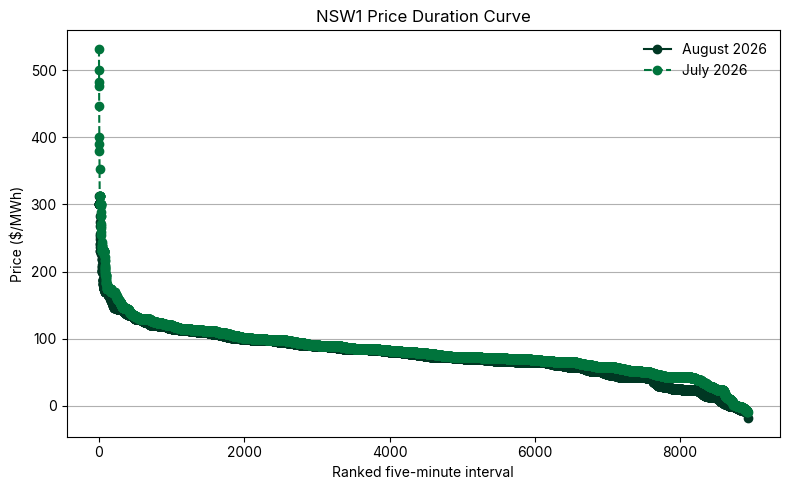

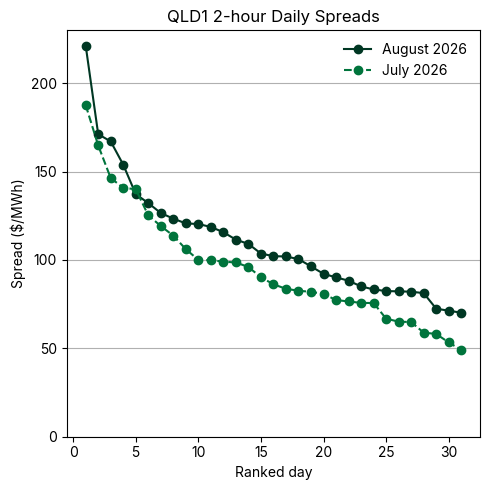

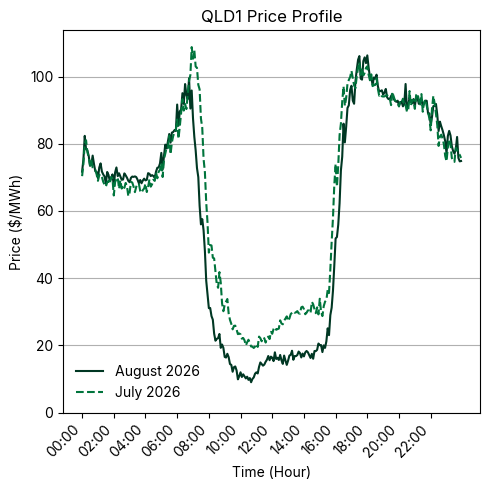

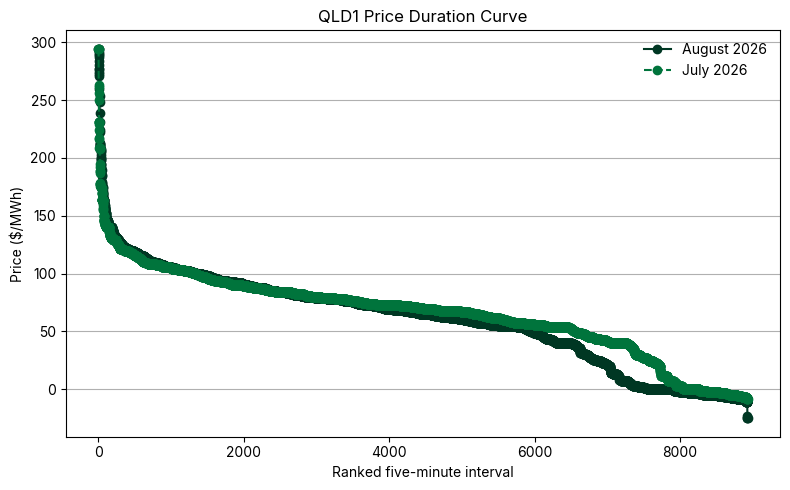

In [4]:
daily_spreads = daily_spreads.copy()
daily_spreads.index = pd.to_datetime(daily_spreads.index)
daily_spreads['Month'] = daily_spreads.index.month
daily_spreads.to_csv(output_path)

previous_month_number = previous_month_start.month
previous_month_name = calendar.month_name[previous_month_number]

for region in target_regions:
    for duration in target_durations[region]:
        duration_column = f'{region}.{duration}'
        current_spreads = daily_spreads[
            daily_spreads['Month'] == month
        ][duration_column].sort_values(ascending=False).reset_index(drop=True)
        previous_spreads = daily_spreads[
            daily_spreads['Month'] == previous_month_number
        ][duration_column].sort_values(ascending=False).reset_index(drop=True)

        plt.figure(figsize=(5, 5))
        plt.plot(
            range(1, len(current_spreads) + 1),
            current_spreads,
            marker='o',
            color=AKAYSHA_PINE,
            label=f'{month_name} {year}',
        )
        plt.plot(
            range(1, len(previous_spreads) + 1),
            previous_spreads,
            marker='o',
            linestyle='--',
            color=AKAYSHA_MOSS,
            label=f'{previous_month_name} {year}',
        )
        plt.xlabel('Ranked day')
        plt.ylabel('Spread ($/MWh)')
        plt.title(f'{region} {duration}-hour Daily Spreads')
        plt.ylim(bottom=0)
        plt.grid(axis='y')
        plt.legend(frameon=False)
        plt.tight_layout()
        plt.show()

    current_price_profile = (
        price_table[price_table['Month'] == month]
        .groupby('Interval')[region]
        .mean()
    )
    previous_price_profile = (
        price_table[price_table['Month'] == previous_month_number]
        .groupby('Interval')[region]
        .mean()
    )
    plt.figure(figsize=(5, 5))
    plt.plot(
        current_price_profile.index,
        current_price_profile,
        color=AKAYSHA_PINE,
        label=f'{month_name} {year}',
    )
    plt.plot(
        previous_price_profile.index,
        previous_price_profile,
        color=AKAYSHA_MOSS,
        label=f'{previous_month_name} {year}',
        linestyle='--',
    )
    plt.xlabel('Time (Hour)')
    plt.ylabel('Price ($/MWh)')
    plt.title(f'{region} Price Profile')
    plt.xticks(
        range(0, 288, 24),
        [f'{hour:02d}:00' for hour in range(0, 24, 2)],
        rotation=45,
        ha='right',
    )
    plt.grid(axis='y')
    plt.ylim(bottom=0)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()

    current_price_duration = price_table[
        price_table['Month'] == month
    ][region].sort_values(ascending=False).reset_index(drop=True)
    previous_price_duration = price_table[
        price_table['Month'] == previous_month_number
    ][region].sort_values(ascending=False).reset_index(drop=True)
    plt.figure(figsize=(8, 5))
    plt.plot(
        range(1, len(current_price_duration) + 1),
        current_price_duration,
        marker='o',
        color=AKAYSHA_PINE,
        label=f'{month_name} {year}',
    )
    plt.plot(
        range(1, len(previous_price_duration) + 1),
        previous_price_duration,
        marker='o',
        color=AKAYSHA_MOSS,
        linestyle='--',
        label=f'{previous_month_name} {year}',
    )
    plt.xlabel('Ranked five-minute interval')
    plt.ylabel('Price ($/MWh)')
    plt.title(f'{region} Price Duration Curve')
    plt.grid(axis='y')
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()


## Generation comparisons

This section retrieves generation for the reporting month, previous month, and previous year. It creates fuel profiles, half-hour averages, comparison deltas, and data-quality reports. Fuel-specific colors and stack ordering are preserved for the generation charts.

In [5]:
generation_data = {}
for region in target_regions:
    generation_data[region] = {
        'current_month': get_fueltype_generation(region, month_start, month_end),
        'previous_month': get_fueltype_generation(
            region, previous_month_start, previous_month_end
        ),
        'previous_year': get_fueltype_generation(
            region, previous_year_start, previous_year_end
        ),
    }

generation_quality_reports = {
    region: {
        comparison: build_time_series_quality_report(
            data, group_columns=['Fuel', 'Region']
        )
        for comparison, data in comparisons.items()
    }
    for region, comparisons in generation_data.items()
}
generation_quality_reports


c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarn

{'NSW1': {'current_month': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_month': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_year': {'row_count': 71424,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []}},
 'QLD1': {'current_month': {'row_count': 62496,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, observed_intervals]
   Index: [],
   'gap_count': 0,
   'gaps': []},
  'previous_month': {'row_count': 62496,
   'duplicate_key_rows': 0,
   'incomplete_days': Empty DataFrame
   Columns: [Fuel, Region, _date, obser

In [6]:
generation_profiles = {
    region: {
        comparison: build_generation_profile(data, region)
        for comparison, data in comparisons.items()
    }
    for region, comparisons in generation_data.items()
}

for region_profiles in generation_profiles.values():
    for profile_name, profile in region_profiles.items():
        if 'Black Coal' in profile.columns:
            region_profiles[profile_name] = profile[
                ['Black Coal']
                + [column for column in profile.columns if column != 'Black Coal']
            ]

generation_half_hour = {
    region: {
        comparison: aggregate_generation_to_half_hour(data)
        for comparison, data in comparisons.items()
    }
    for region, comparisons in generation_data.items()
}
generation_profiles[target_regions[0]]['current_month'].head()


Fuel,Black Coal,Battery,Diesel,Gas,Hydro,Natural Gas (Pipeline),Solar,Wind
Interval,,,,,,,,
0,5845.937526,37.581347,0.0,35.483871,406.991247,0.0,0.0,855.796637
1,5814.213847,41.741935,0.0,35.944675,417.873011,0.0,0.0,858.721683
2,5836.867578,46.365243,0.0,35.507407,433.213035,0.0,0.0,858.380792
3,5824.983568,42.625402,0.0,35.084121,436.825127,0.0,0.0,859.963854
4,5816.593260,32.129032,0.0,35.483871,435.607016,0.0,0.0,861.845369


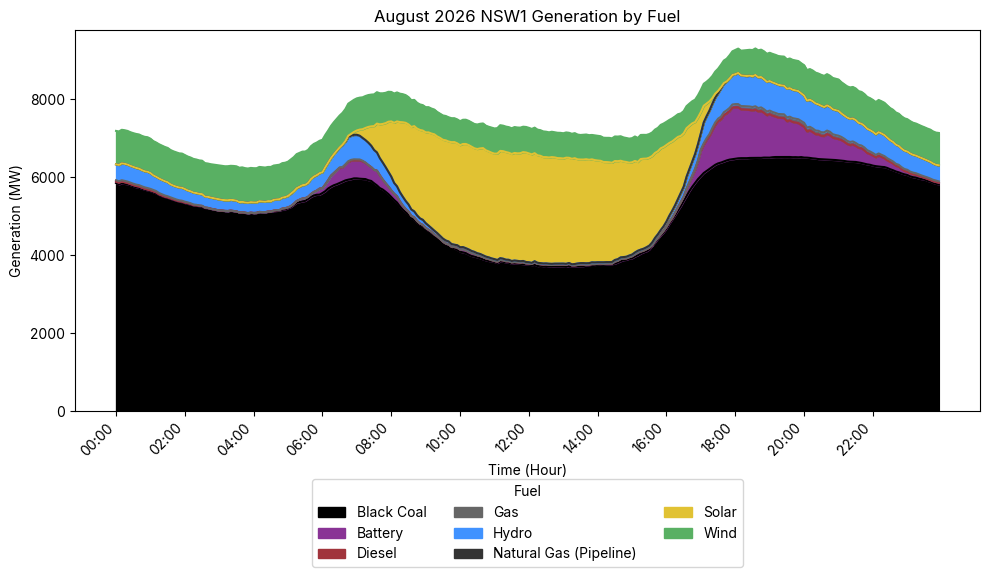

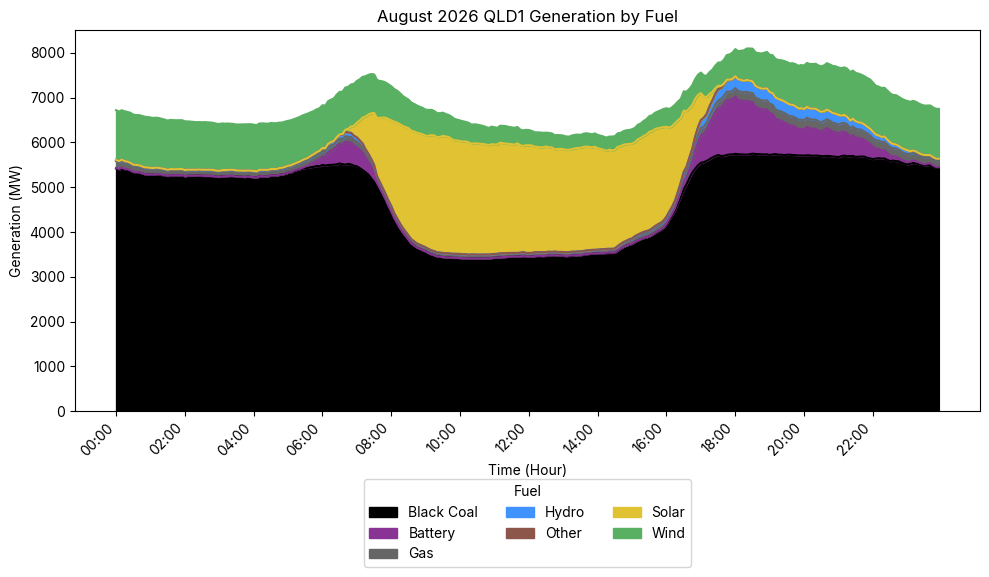

In [7]:
generation_colour_map = {
    'Black Coal': '#000000',
    'Brown Coal': '#73361C',
    'Gas': '#666666',
    'Diesel': '#A1343C',
    'Hydro': '#4092FF',
    'Wind': '#59B063',
    'Solar': '#E1C233',
    'Battery': '#893395',
    'Other': '#8c564b',
}

for region in target_regions:
    with plt.rc_context({
        'text.color': 'black',
        'axes.labelcolor': 'black',
        'axes.titlecolor': 'black',
        'axes.edgecolor': 'black',
        'axes.facecolor': 'white',
        'figure.facecolor': 'white',
        'savefig.facecolor': 'white',
        'grid.color': '#B0B0B0',
    }):
        generation_profiles[region]['current_month'].plot(
            kind='area',
            stacked=True,
            figsize=(10, 6),
            color=[
                generation_colour_map.get(fuel, '#333333')
                for fuel in generation_profiles[region]['current_month'].columns
            ],
        )
        plt.xlabel('Time (Hour)')
        plt.ylabel('Generation (MW)')
        plt.title(f'{month_name} {year} {region} Generation by Fuel')
        plt.xticks(
            range(0, 288, 24),
            [f'{hour:02d}:00' for hour in range(0, 24, 2)],
            rotation=45,
            ha='right',
        )
        plt.legend(
            title='Fuel',
            loc='upper center',
            bbox_to_anchor=(0.5, -0.16),
            ncol=3,
            frameon=True,
        )
        plt.tight_layout()
        plt.show()


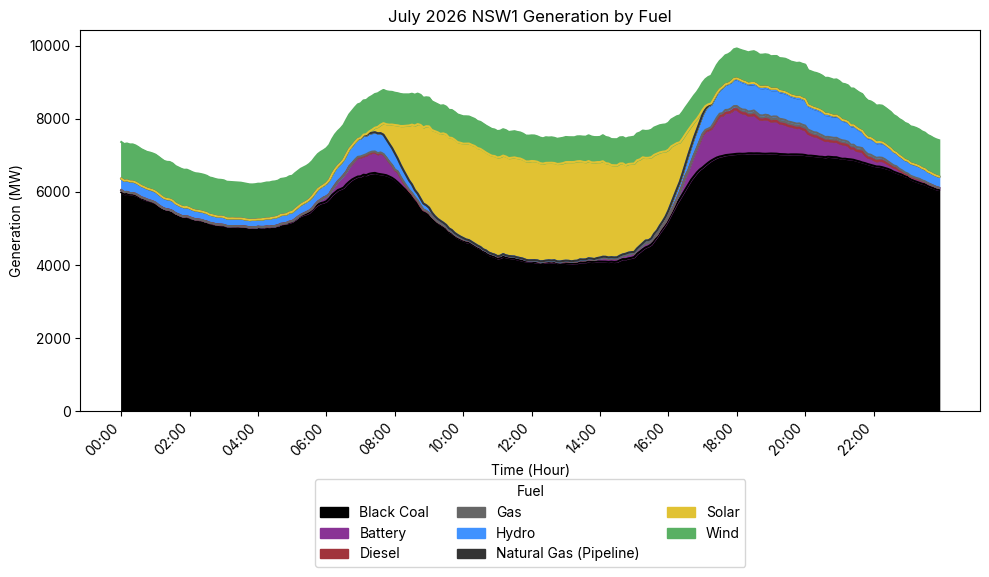

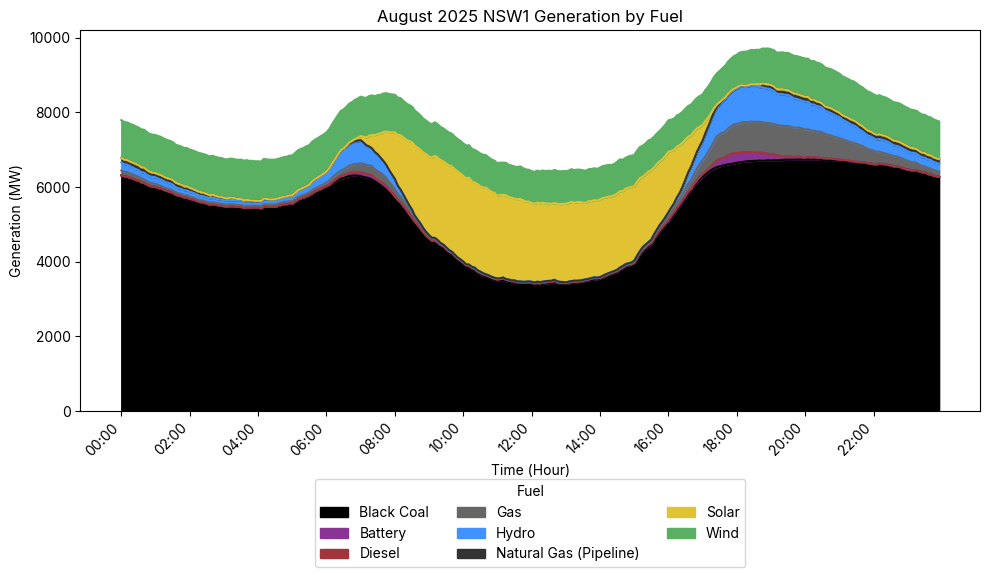

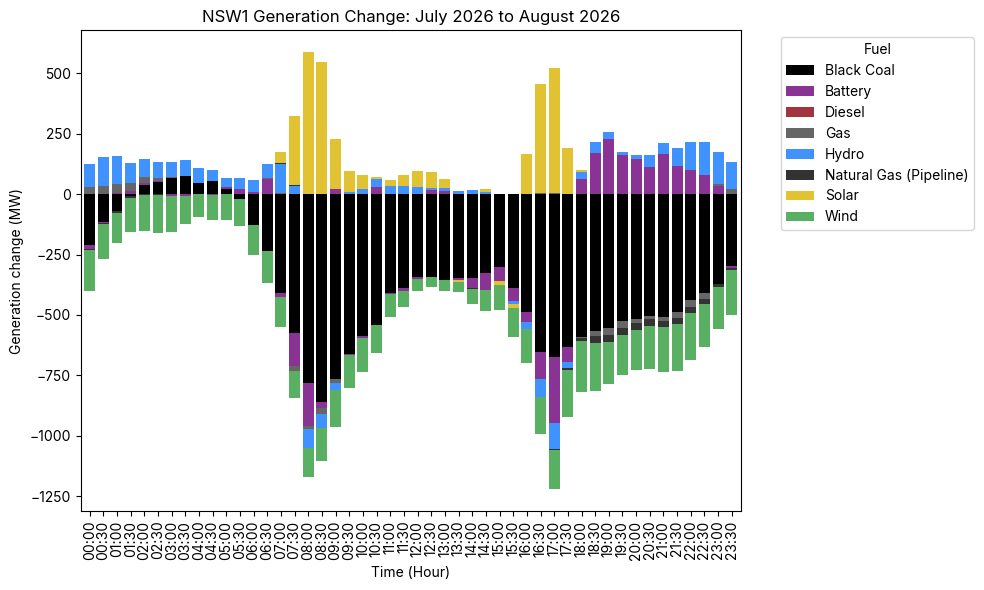

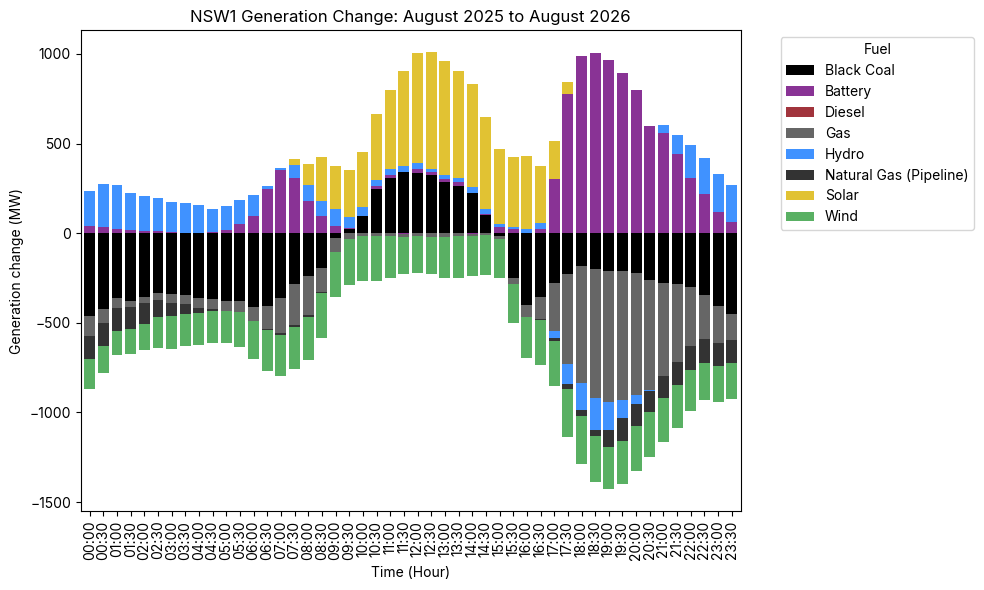

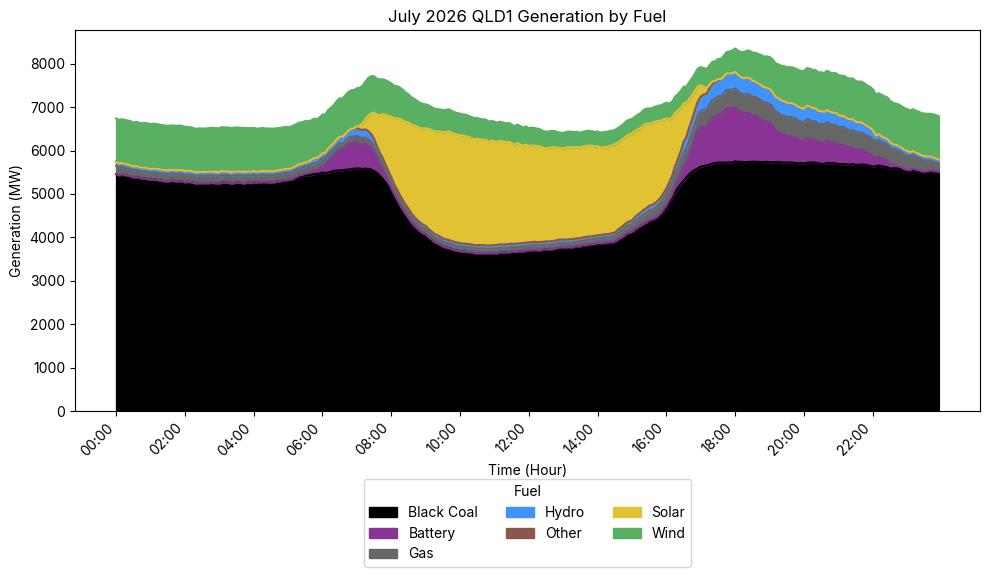

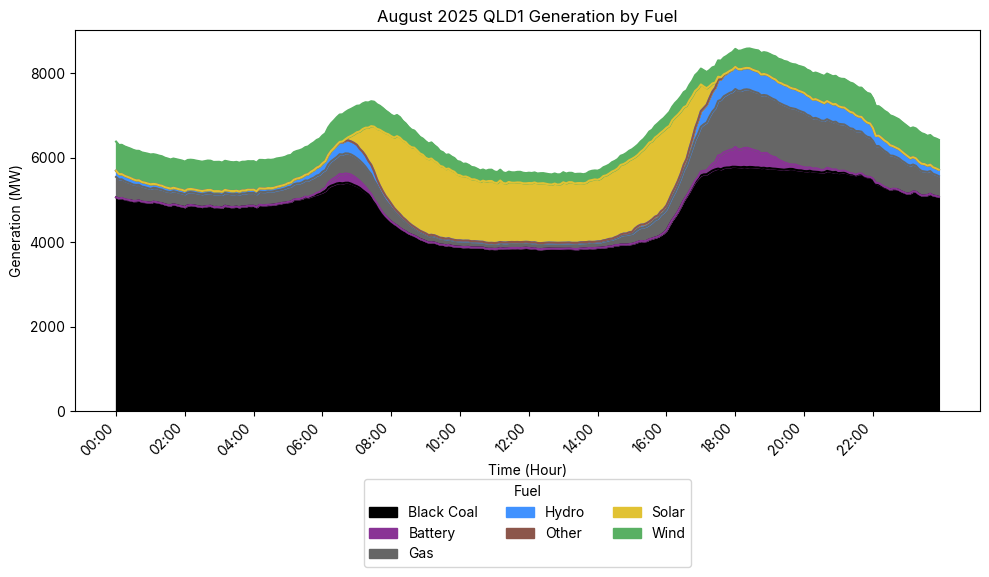

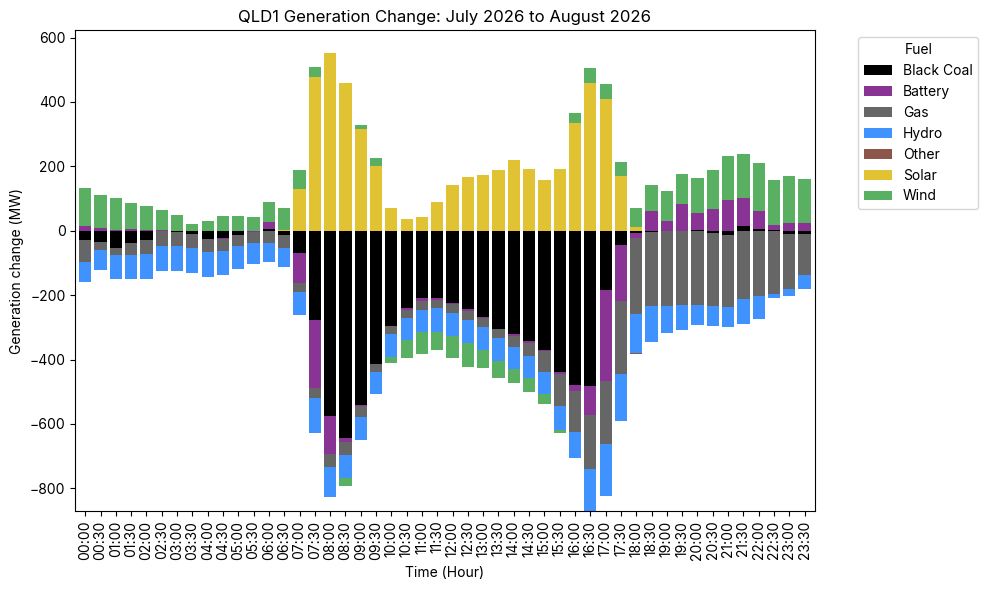

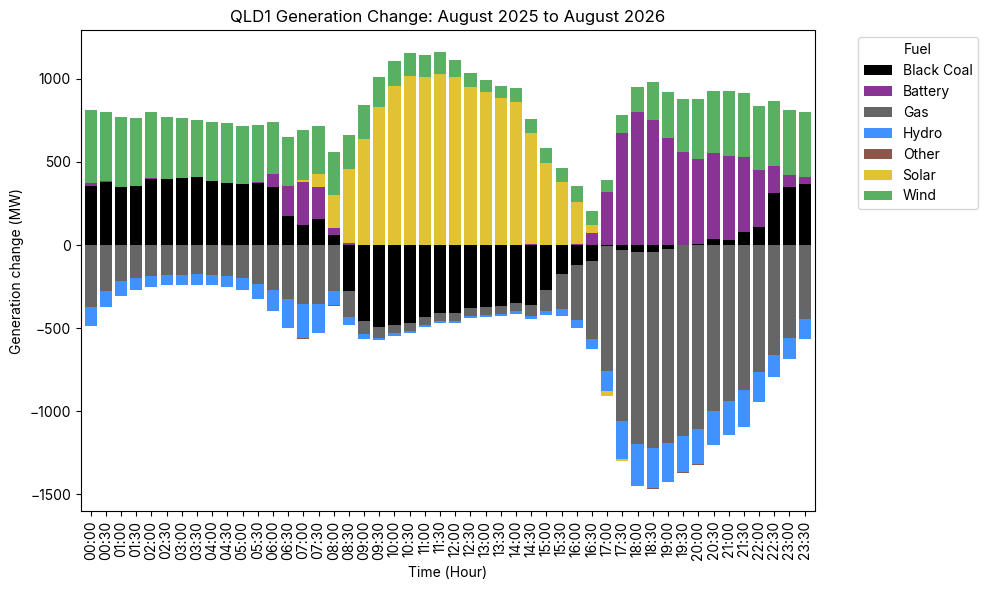

In [8]:
for region in target_regions:
    for profile_name, profile_title in [
        ('previous_month', f'{calendar.month_name[previous_month_start.month]} {year}'),
        ('previous_year', f'{month_name} {year - 1}'),
    ]:
        with plt.rc_context({
            'text.color': 'black',
            'axes.labelcolor': 'black',
            'axes.titlecolor': 'black',
            'axes.edgecolor': 'black',
            'axes.facecolor': 'white',
            'figure.facecolor': 'white',
            'savefig.facecolor': 'white',
            'grid.color': '#B0B0B0',
        }):
            generation_profiles[region][profile_name].plot(
                kind='area',
                stacked=True,
                figsize=(10, 6),
                color=[
                    generation_colour_map.get(fuel, '#333333')
                    for fuel in generation_profiles[region][profile_name].columns
                ],
            )
            plt.xlabel('Time (Hour)')
            plt.ylabel('Generation (MW)')
            plt.title(f'{profile_title} {region} Generation by Fuel')
            plt.xticks(
                range(0, 288, 24),
                [f'{hour:02d}:00' for hour in range(0, 24, 2)],
                rotation=45,
                ha='right',
            )
            plt.legend(
                title='Fuel',
                loc='upper center',
                bbox_to_anchor=(0.5, -0.16),
                ncol=3,
                frameon=True,
            )
            plt.tight_layout()
            plt.show()

    current_generation_by_half_hour = generation_half_hour[region]['current_month'].query(
        'Region == @region'
    )
    previous_generation_by_half_hour = generation_half_hour[region]['previous_month'].query(
        'Region == @region'
    )
    previous_year_generation_by_half_hour = generation_half_hour[region]['previous_year'].query(
        'Region == @region'
    )
    current_generation_profile = current_generation_by_half_hour.groupby(
        ['HH', 'Fuel'], as_index=False
    )['Generation'].mean().pivot(index='HH', columns='Fuel', values='Generation')
    previous_generation_profile = previous_generation_by_half_hour.groupby(
        ['HH', 'Fuel'], as_index=False
    )['Generation'].mean().pivot(index='HH', columns='Fuel', values='Generation')
    previous_year_generation_profile = previous_year_generation_by_half_hour.groupby(
        ['HH', 'Fuel'], as_index=False
    )['Generation'].mean().pivot(index='HH', columns='Fuel', values='Generation')

    generation_deltas = {
        'previous_month': current_generation_profile - previous_generation_profile,
        'previous_year': current_generation_profile - previous_year_generation_profile,
    }
    for comparison_name, delta in generation_deltas.items():
        ordered_columns = ['Black Coal'] + [
            column for column in delta.columns if column != 'Black Coal'
        ]
        delta = delta.reindex(columns=ordered_columns).copy()
        delta.index = half_hour_time_labels(delta.index).strftime('%H:%M')
        ax = delta.plot(
            kind='bar',
            stacked=True,
            figsize=(10, 6),
            width=0.8,
            color=[generation_colour_map.get(fuel, '#333333') for fuel in delta.columns],
        )
        comparison_label = (
            f'{calendar.month_name[previous_month_start.month]} {year}'
            if comparison_name == 'previous_month'
            else f'{month_name} {year - 1}'
        )
        plt.xlabel('Time (Hour)')
        plt.ylabel('Generation change (MW)')
        plt.title(f'{region} Generation Change: {comparison_label} to {month_name} {year}')
        plt.legend(title='Fuel', bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()


## Baseload and demand

This section calculates monthly baseload averages and half-hour operational-demand profiles for the reporting month, previous month, and previous year.

In [9]:
baseload = price_table[regions].copy()
baseload['Year'] = baseload.index.year
baseload['Month'] = baseload.index.month
baseload_monthly = baseload.groupby(['Year', 'Month'])[regions].mean()
baseload_monthly.tail()

REGIONID         NSW1       QLD1        SA1       TAS1       VIC1
Year Month                                                       
2026 7      81.521159  65.434909  95.878807  71.032298  70.352604
     8      75.710800  60.425349  71.628728  57.960130  60.410138
     9      64.950000  55.010000  28.530000  27.150000  13.730000

c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(
c:\anaconda3\Lib\site-packages\urllib3\connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.neopoint.com.au'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


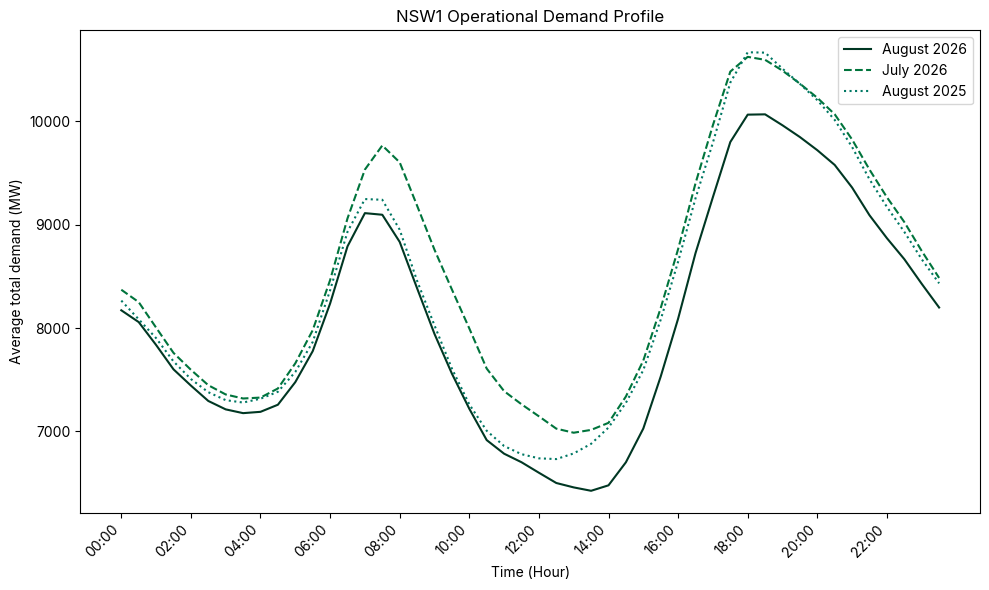

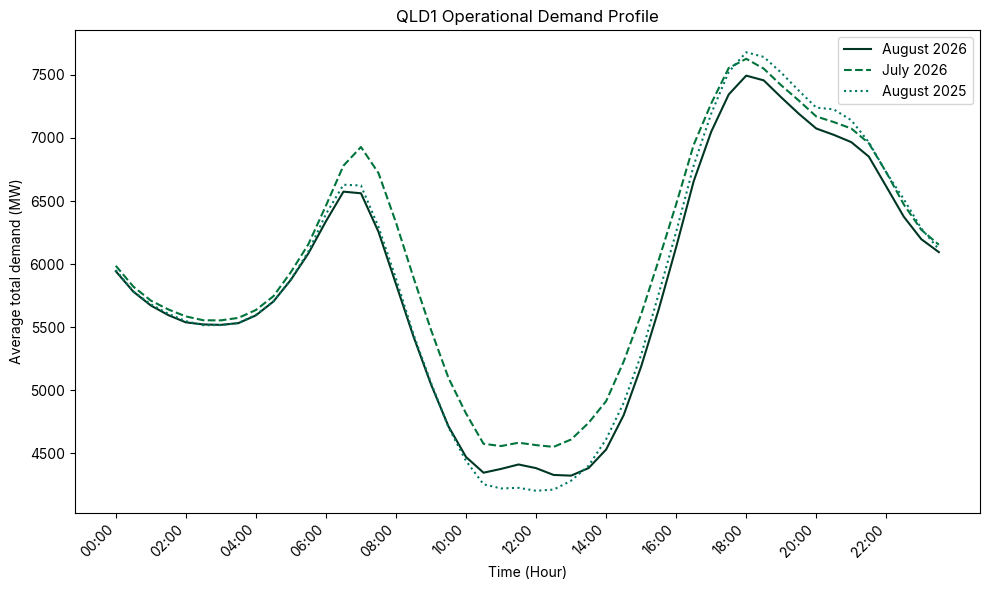

In [10]:
demand_current = get_operational_demand(month_start, month_end)
demand_previous = get_operational_demand(
    previous_month_start, previous_month_end
)
demand_previous_year = get_operational_demand(previous_year_start, previous_year_end)

demand_profiles = {
    'current_month': average_demand_by_half_hour(demand_current),
    'previous_month': average_demand_by_half_hour(demand_previous),
    'previous_year': average_demand_by_half_hour(demand_previous_year),
}

for region in target_regions:
    plt.figure(figsize=(10, 6))
    for profile_name, label, line_style, color in [
        ('current_month', f'{month_name} {year}', '-', AKAYSHA_PINE),
        ('previous_month', f'{previous_month_name} {year}', '--', AKAYSHA_MOSS),
        ('previous_year', f'{month_name} {year - 1}', ':', AKAYSHA_JADE),
    ]:
        region_demand = demand_profiles[profile_name]
        region_demand = region_demand[region_demand['REGIONID'] == region]
        plt.plot(
            region_demand['HH'],
            region_demand['TOTALDEMAND'],
            label=label,
            linestyle=line_style,
            color=color,
        )
    plt.xlabel('Time (Hour)')
    plt.ylabel('Average total demand (MW)')
    plt.title(f'{region} Operational Demand Profile')
    plt.xticks(
        range(0, 48, 4),
        [f'{hour:02d}:00' for hour in range(0, 24, 2)],
        rotation=45,
        ha='right',
    )
    plt.legend()
    plt.tight_layout()
    plt.show()


## Gas-weighted price

This section combines half-hour NSW1 generation and price data to calculate and plot the generation-weighted gas price for the reporting period.

NSW1 average gas-weighted price: 117.61 $/MWh


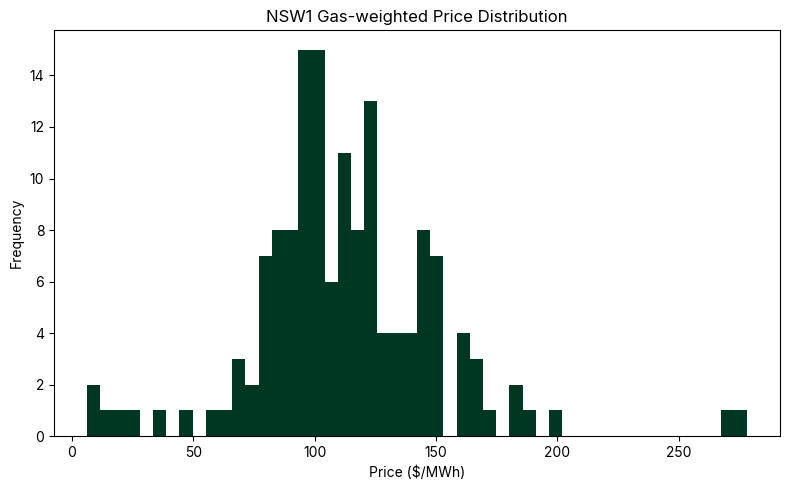

QLD1 average gas-weighted price: 78.07 $/MWh


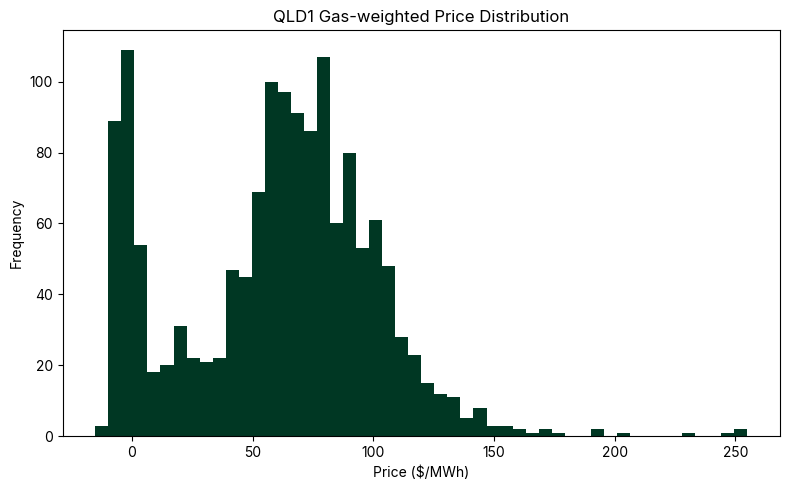

In [11]:
gas_weighted_prices = {}
for region in target_regions:
    gas_generation = generation_half_hour[region]['current_month'].query(
        "Fuel == 'Gas'"
    ).copy()
    price_half_hour = aggregate_to_half_hour(
        price_data[price_data['REGIONID'] == region],
        'Trading Price_5min',
        ['REGIONID'],
    )
    gas_price_data = price_half_hour.merge(
        gas_generation,
        on='SETTLEMENTDATE',
        how='left',
    )
    gas_price_data = gas_price_data[gas_price_data['Generation'] > 0].copy()
    gas_price_data = gas_price_data.rename(columns={'Trading Price_5min': 'Price'})
    gas_weighted_prices[region] = calculate_gas_weighted_price(gas_price_data)

    print(
        f'{region} average gas-weighted price: '
        f'{gas_weighted_prices[region]:.2f} $/MWh'
    )
    gas_price_data['Price'].plot(
        kind='hist',
        bins=50,
        figsize=(8, 5),
        title=f'{region} Gas-weighted Price Distribution',
        color=AKAYSHA_PINE,
    )
    plt.xlabel('Price ($/MWh)')
    plt.tight_layout()
    plt.show()


## Specific day investigations

Enter an inclusive date or date range and one of the configured target regions in the cell below. The charts use the raw five-minute data loaded earlier in the notebook and aggregate it to half-hour settlement periods for readability. Dates must be within the price, generation, and demand periods loaded above.

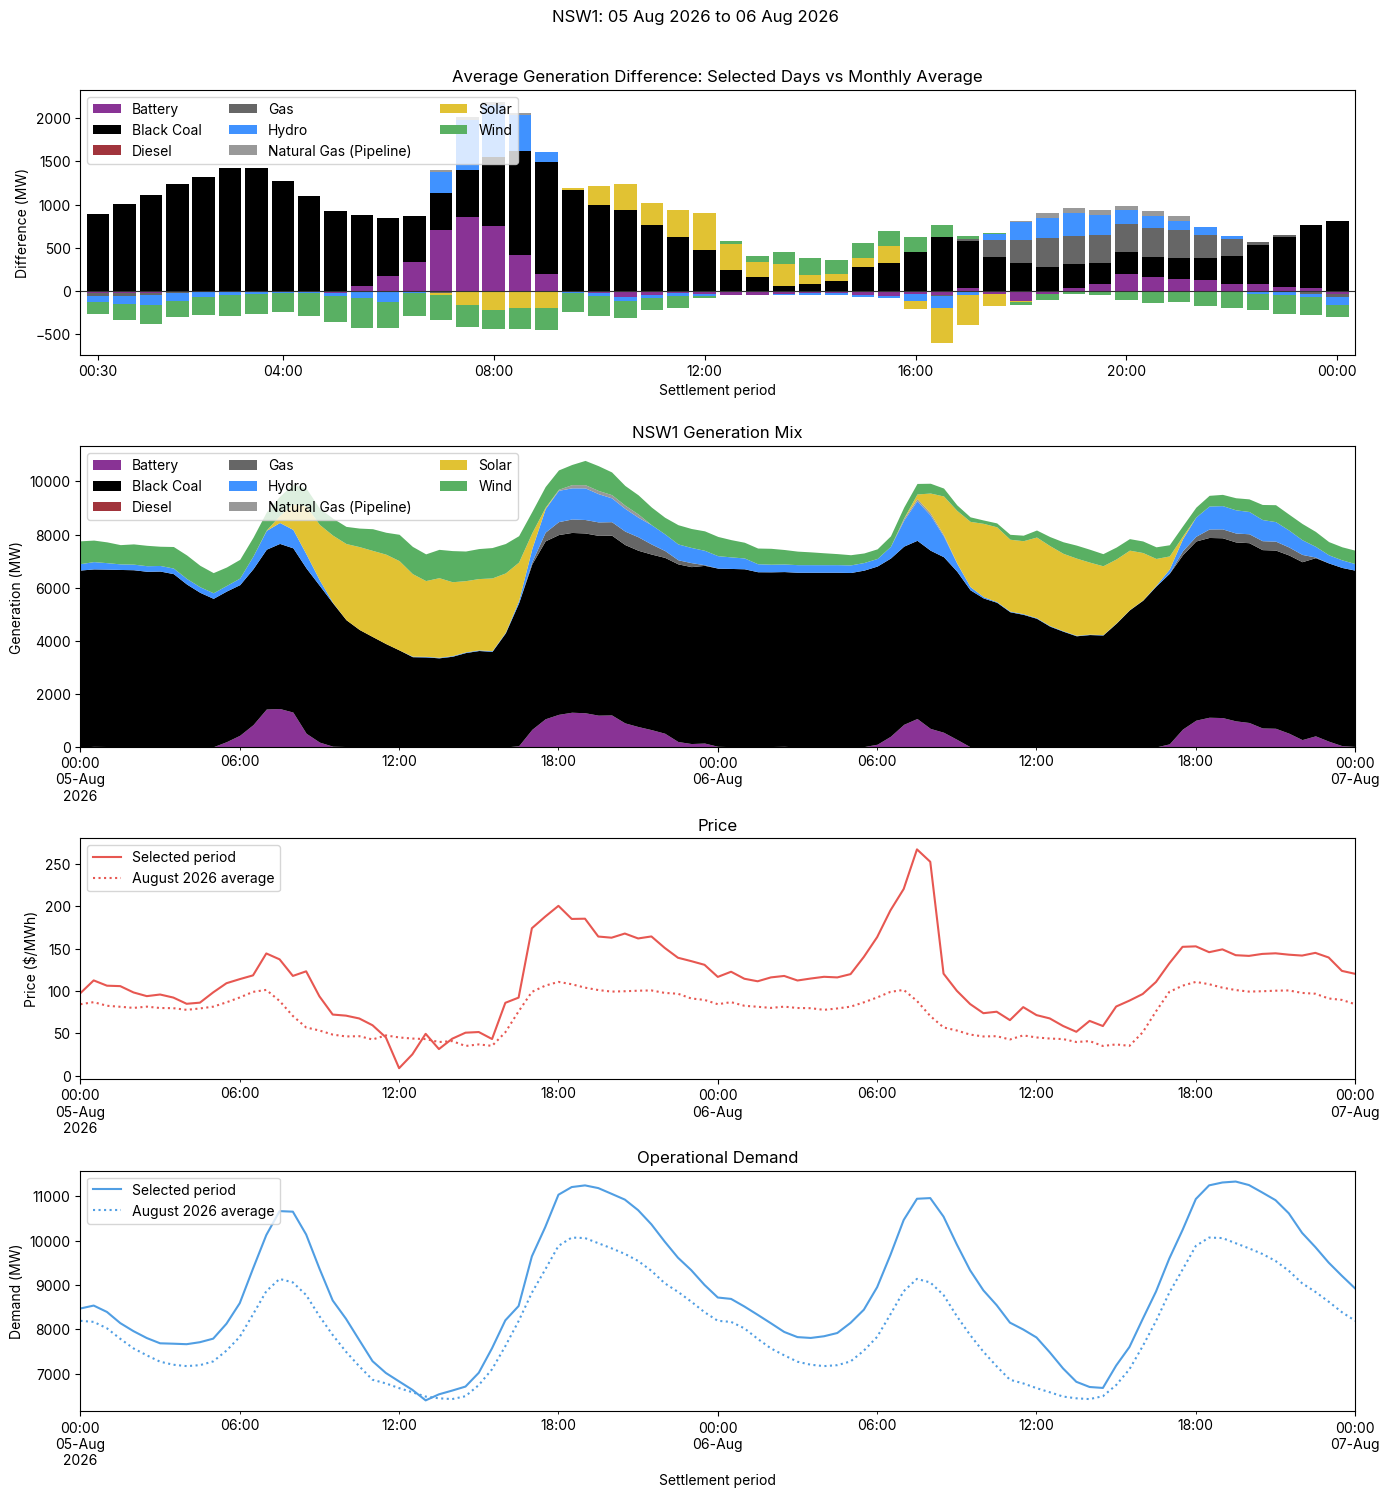

In [12]:
# Investigation inputs. The end date is inclusive.
investigation_start = dt.date(2026, 8, 5)
investigation_end = dt.date(2026, 8, 6)
investigation_region = 'NSW1'


# ------------------------------------------------------------------
# Validation and date boundaries
# ------------------------------------------------------------------

if investigation_start > investigation_end:
    raise ValueError(
        'investigation_start must be on or before investigation_end'
    )

if investigation_region not in target_regions:
    raise ValueError(
        f'investigation_region must be one of the loaded target regions: '
        f'{target_regions}'
    )

if (
    investigation_start.year != investigation_end.year
    or investigation_start.month != investigation_end.month
):
    raise ValueError(
        'The investigation period must fall within a single calendar month.'
    )

investigation_start_timestamp = pd.Timestamp(investigation_start)

# Exclusive upper bound. This includes every interval on investigation_end.
investigation_end_timestamp = (
    pd.Timestamp(investigation_end)
    + pd.Timedelta(days=1)
)

month_start_timestamp = investigation_start_timestamp.replace(day=1)
month_end_timestamp = month_start_timestamp + pd.offsets.MonthBegin(1)


# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------

def settlement_day(data, timestamp_column='SETTLEMENTDATE'):
    """
    Assign each timestamp to its NEM settlement day.

    The one-minute adjustment assigns midnight to the preceding
    settlement day.
    """
    timestamps = pd.to_datetime(data[timestamp_column])

    return (
        timestamps
        - pd.Timedelta(minutes=1)
    ).dt.normalize()


def settlement_period(data, timestamp_column='SETTLEMENTDATE'):
    """
    Return the half-hour settlement period number from 1 to 48.

    The one-minute adjustment assigns 00:00 to period 48 of the
    preceding settlement day.
    """
    timestamps = (
        pd.to_datetime(data[timestamp_column])
        - pd.Timedelta(minutes=1)
    )

    return (
        timestamps.dt.hour * 2
        + timestamps.dt.minute // 30
        + 1
    )


def half_hour_settlement_period(timestamp_index):
    """
    Map a right-labelled DatetimeIndex to settlement periods 1 to 48.
    """
    adjusted_index = timestamp_index - pd.Timedelta(minutes=1)

    return (
        adjusted_index.hour * 2
        + adjusted_index.minute // 30
        + 1
    )


def create_profile_overlay(timestamp_index, profile):
    """
    Repeat a 48-period monthly-average profile across a DatetimeIndex.
    """
    periods = half_hour_settlement_period(timestamp_index)

    return pd.Series(
        [profile.get(period, np.nan) for period in periods],
        index=timestamp_index,
        name='Monthly average',
    )


# ------------------------------------------------------------------
# Combine the loaded source datasets
# ------------------------------------------------------------------

all_generation = pd.concat(
    [
        comparison_data
        for region_data in generation_data.values()
        for comparison_data in region_data.values()
    ],
    ignore_index=True,
).drop_duplicates()

all_generation['SETTLEMENTDATE'] = pd.to_datetime(
    all_generation['SETTLEMENTDATE']
)
all_generation['SettlementDay'] = settlement_day(all_generation)
all_generation['SettlementPeriod'] = settlement_period(all_generation)


all_prices = price_data.copy()

all_prices['SETTLEMENTDATE'] = pd.to_datetime(
    all_prices['SETTLEMENTDATE']
)
all_prices['SettlementDay'] = settlement_day(all_prices)
all_prices['SettlementPeriod'] = settlement_period(all_prices)


all_demand = pd.concat(
    [
        demand_current,
        demand_previous,
        demand_previous_year,
    ],
    ignore_index=True,
).drop_duplicates()

all_demand['SETTLEMENTDATE'] = pd.to_datetime(
    all_demand['SETTLEMENTDATE']
)
all_demand['SettlementDay'] = settlement_day(all_demand)
all_demand['SettlementPeriod'] = settlement_period(all_demand)


# ------------------------------------------------------------------
# Filter the selected investigation period
# ------------------------------------------------------------------

loaded_generation = all_generation[
    (all_generation['Region'] == investigation_region)
    & (
        all_generation['SETTLEMENTDATE']
        >= investigation_start_timestamp
    )
    & (
        all_generation['SETTLEMENTDATE']
        < investigation_end_timestamp
    )
].copy()


investigation_prices = all_prices[
    (all_prices['REGIONID'] == investigation_region)
    & (
        all_prices['SETTLEMENTDATE']
        >= investigation_start_timestamp
    )
    & (
        all_prices['SETTLEMENTDATE']
        < investigation_end_timestamp
    )
].copy()


investigation_demand = all_demand[
    (all_demand['REGIONID'] == investigation_region)
    & (
        all_demand['SETTLEMENTDATE']
        >= investigation_start_timestamp
    )
    & (
        all_demand['SETTLEMENTDATE']
        < investigation_end_timestamp
    )
].copy()


# ------------------------------------------------------------------
# Filter the full calendar month for comparison profiles
# ------------------------------------------------------------------

monthly_generation = all_generation[
    (all_generation['Region'] == investigation_region)
    & (
        all_generation['SETTLEMENTDATE']
        >= month_start_timestamp
    )
    & (
        all_generation['SETTLEMENTDATE']
        < month_end_timestamp
    )
].copy()


monthly_prices = all_prices[
    (all_prices['REGIONID'] == investigation_region)
    & (
        all_prices['SETTLEMENTDATE']
        >= month_start_timestamp
    )
    & (
        all_prices['SETTLEMENTDATE']
        < month_end_timestamp
    )
].copy()


monthly_demand = all_demand[
    (all_demand['REGIONID'] == investigation_region)
    & (
        all_demand['SETTLEMENTDATE']
        >= month_start_timestamp
    )
    & (
        all_demand['SETTLEMENTDATE']
        < month_end_timestamp
    )
].copy()


# ------------------------------------------------------------------
# Check that the required data is available
# ------------------------------------------------------------------

if (
    loaded_generation.empty
    or investigation_prices.empty
    or investigation_demand.empty
):
    raise ValueError(
        'The selected date range has incomplete data for '
        f'{investigation_region}. Check that it is within the '
        'periods loaded above.'
    )

if (
    monthly_generation.empty
    or monthly_prices.empty
    or monthly_demand.empty
):
    raise ValueError(
        'Monthly comparison data is incomplete for '
        f'{investigation_region} in '
        f'{month_start_timestamp:%B %Y}.'
    )


# ------------------------------------------------------------------
# Resample selected-period data to half-hour resolution
# ------------------------------------------------------------------

generation_half_hour = (
    loaded_generation
    .groupby(
        [
            pd.Grouper(
                key='SETTLEMENTDATE',
                freq='30min',
                label='right',
                closed='right',
            ),
            'Fuel',
        ],
        as_index=False,
    )['Generation']
    .mean()
    .pivot(
        index='SETTLEMENTDATE',
        columns='Fuel',
        values='Generation',
    )
    .fillna(0)
    .sort_index()
)


price_half_hour = (
    investigation_prices
    .set_index('SETTLEMENTDATE')['Trading Price_5min']
    .resample(
        '30min',
        label='right',
        closed='right',
    )
    .mean()
    .sort_index()
)


demand_half_hour = (
    investigation_demand
    .set_index('SETTLEMENTDATE')['TOTALDEMAND']
    .resample(
        '30min',
        label='right',
        closed='right',
    )
    .mean()
    .sort_index()
)


# ------------------------------------------------------------------
# Selected-days average generation profile
# ------------------------------------------------------------------

selected_generation_profile_data = generation_half_hour.copy()

selected_generation_profile_data['SettlementPeriod'] = (
    half_hour_settlement_period(
        selected_generation_profile_data.index
    )
)

selected_generation_profile = (
    selected_generation_profile_data
    .groupby('SettlementPeriod')
    .mean()
    .reindex(range(1, 49))
    .fillna(0)
)


# ------------------------------------------------------------------
# Monthly-average generation profile
# ------------------------------------------------------------------

# First calculate fuel generation for each underlying timestamp.
monthly_generation_interval = (
    monthly_generation
    .groupby(
        [
            'SETTLEMENTDATE',
            'SettlementDay',
            'SettlementPeriod',
            'Fuel',
        ],
        as_index=False,
    )['Generation']
    .mean()
)

# Then average across all days in the month by settlement period.
monthly_generation_profile = (
    monthly_generation_interval
    .groupby(
        [
            'SettlementPeriod',
            'Fuel',
        ],
        as_index=False,
    )['Generation']
    .mean()
    .pivot(
        index='SettlementPeriod',
        columns='Fuel',
        values='Generation',
    )
    .reindex(range(1, 49))
    .fillna(0)
)


# Ensure both generation profiles use the same fuel columns.
all_fuels = sorted(
    set(selected_generation_profile.columns)
    | set(monthly_generation_profile.columns)
)

selected_generation_profile = (
    selected_generation_profile
    .reindex(
        index=range(1, 49),
        columns=all_fuels,
        fill_value=0,
    )
)

monthly_generation_profile = (
    monthly_generation_profile
    .reindex(
        index=range(1, 49),
        columns=all_fuels,
        fill_value=0,
    )
)


# Positive values mean the selected days had more generation than
# the monthly average. Negative values mean they had less.
generation_difference_profile = (
    selected_generation_profile
    - monthly_generation_profile
)


# ------------------------------------------------------------------
# Monthly-average price profile
# ------------------------------------------------------------------

# Calculate a half-hour price for every settlement day and period.
monthly_price_by_day = (
    monthly_prices
    .groupby(
        [
            'SettlementDay',
            'SettlementPeriod',
        ],
        as_index=False,
    )['Trading Price_5min']
    .mean()
)

# Average the corresponding settlement periods across the month.
monthly_price_profile = (
    monthly_price_by_day
    .groupby('SettlementPeriod')['Trading Price_5min']
    .mean()
    .reindex(range(1, 49))
)


# ------------------------------------------------------------------
# Monthly-average operational-demand profile
# ------------------------------------------------------------------

monthly_demand_by_day = (
    monthly_demand
    .groupby(
        [
            'SettlementDay',
            'SettlementPeriod',
        ],
        as_index=False,
    )['TOTALDEMAND']
    .mean()
)

monthly_demand_profile = (
    monthly_demand_by_day
    .groupby('SettlementPeriod')['TOTALDEMAND']
    .mean()
    .reindex(range(1, 49))
)


# ------------------------------------------------------------------
# Repeat monthly profiles across the selected period
# ------------------------------------------------------------------

price_monthly_overlay = create_profile_overlay(
    price_half_hour.index,
    monthly_price_profile,
)

demand_monthly_overlay = create_profile_overlay(
    demand_half_hour.index,
    monthly_demand_profile,
)


# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

figure, axes = plt.subplots(
    4,
    1,
    figsize=(14, 15),
    sharex=False,
    gridspec_kw={
        'height_ratios': [1.1, 1.25, 1, 1],
    },
)


# Generation difference from monthly average
generation_difference_profile.plot(
    kind='bar',
    stacked=True,
    ax=axes[0],
    width=0.85,
    color=[
        generation_colour_map.get(fuel, '#999999')
        for fuel in generation_difference_profile.columns
    ],
)

axes[0].axhline(
    y=0,
    color='#333333',
    linewidth=0.8,
)

axes[0].set_title(
    'Average Generation Difference: '
    'Selected Days vs Monthly Average'
)
axes[0].set_ylabel('Difference (MW)')
axes[0].set_xlabel('Settlement period')
axes[0].legend(
    loc='upper left',
    ncol=3,
    title=None,
)

axes[0].set_xticks(
    [0, 7, 15, 23, 31, 39, 47]
)
axes[0].set_xticklabels(
    [
        '00:30',
        '04:00',
        '08:00',
        '12:00',
        '16:00',
        '20:00',
        '00:00',
    ],
    rotation=0,
)


# Selected-period generation mix
generation_half_hour.plot.area(
    ax=axes[1],
    stacked=True,
    color=[
        generation_colour_map.get(fuel, '#999999')
        for fuel in generation_half_hour.columns
    ],
    linewidth=0,
)

axes[1].set_title(
    f'{investigation_region} Generation Mix'
)
axes[1].set_ylabel('Generation (MW)')
axes[1].set_xlabel('')
axes[1].legend(
    loc='upper left',
    ncol=3,
    title=None,
)


# Price and monthly-average price profile
price_half_hour.plot(
    ax=axes[2],
    color=AKAYSHA_AMARANTH,
    linewidth=1.5,
    label='Selected period',
)

price_monthly_overlay.plot(
    ax=axes[2],
    color=AKAYSHA_AMARANTH,
    linewidth=1.5,
    linestyle=':',
    label=f'{month_start_timestamp:%B %Y} average',
)

axes[2].set_title('Price')
axes[2].set_ylabel('Price ($/MWh)')
axes[2].set_xlabel('')
axes[2].legend(loc='upper left')


# Demand and monthly-average operational-demand profile
demand_half_hour.plot(
    ax=axes[3],
    color=AKAYSHA_AZURE,
    linewidth=1.5,
    label='Selected period',
)

demand_monthly_overlay.plot(
    ax=axes[3],
    color=AKAYSHA_AZURE,
    linewidth=1.5,
    linestyle=':',
    label=f'{month_start_timestamp:%B %Y} average',
)

axes[3].set_title('Operational Demand')
axes[3].set_ylabel('Demand (MW)')
axes[3].set_xlabel('Settlement period')
axes[3].legend(loc='upper left')


figure.suptitle(
    f'{investigation_region}: '
    f'{investigation_start:%d %b %Y} to '
    f'{investigation_end:%d %b %Y}',
    y=0.995,
)

figure.tight_layout(
    rect=[0, 0, 1, 0.985]
)

plt.show()